# Exercise: the Challenger launch

On January 28, 1986, the space shuttle Challenger broke apart 73 seconds after launch. All seven crew members died. The cause was an **O-ring**: a rubber seal in a rocket booster. It failed in the cold.

The night before, engineers and managers had to decide: is it safe to launch? The forecast was **31°F**. No shuttle had ever launched below 53°F.

You have the data they had: 23 earlier flights. Today you fit a logistic regression and predict the risk at 31°F.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## The data

Each row is one flight before Challenger.

| column | meaning |
|---|---|
| `flight` | launch order, 1–23 |
| `temp` | temperature at launch (°F) |
| `pressure` | leak-check pressure (psi) |
| `o_rings` | O-rings at risk (always 6) |
| `distress` | how many O-rings were damaged |
| `damage` | 1 if any O-ring was damaged, 0 if not |

Source: UCI Machine Learning Repository, "Challenger USA Space Shuttle O-Ring" (Draper, 1993; Dalal, Fowlkes & Hoadley, 1989).

The Challenger launch itself is **not** in the data. It is the flight we want to predict.

In tidymodels, a yes/no outcome must be a **factor**. We put `no` first so that `yes` is the event the model predicts.

In [2]:
challenger <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/challenger.csv')

challenger <- challenger |>
    mutate(damage_f = factor(damage, levels = c(0, 1), labels = c('no', 'yes')))

challenger |> count(damage_f)

  damage_f n 
1 no       16
2 yes       7

## 1. Look at the data

Plot `damage` (y-axis) against `temp` (x-axis). Jitter the points up and down a little so you can see them all.

<details>
<summary>Hint</summary>

```R
ggplot(challenger, aes(x = temp, y = damage)) +
    geom_jitter(width = 0, height = 0.05)
```

</details>

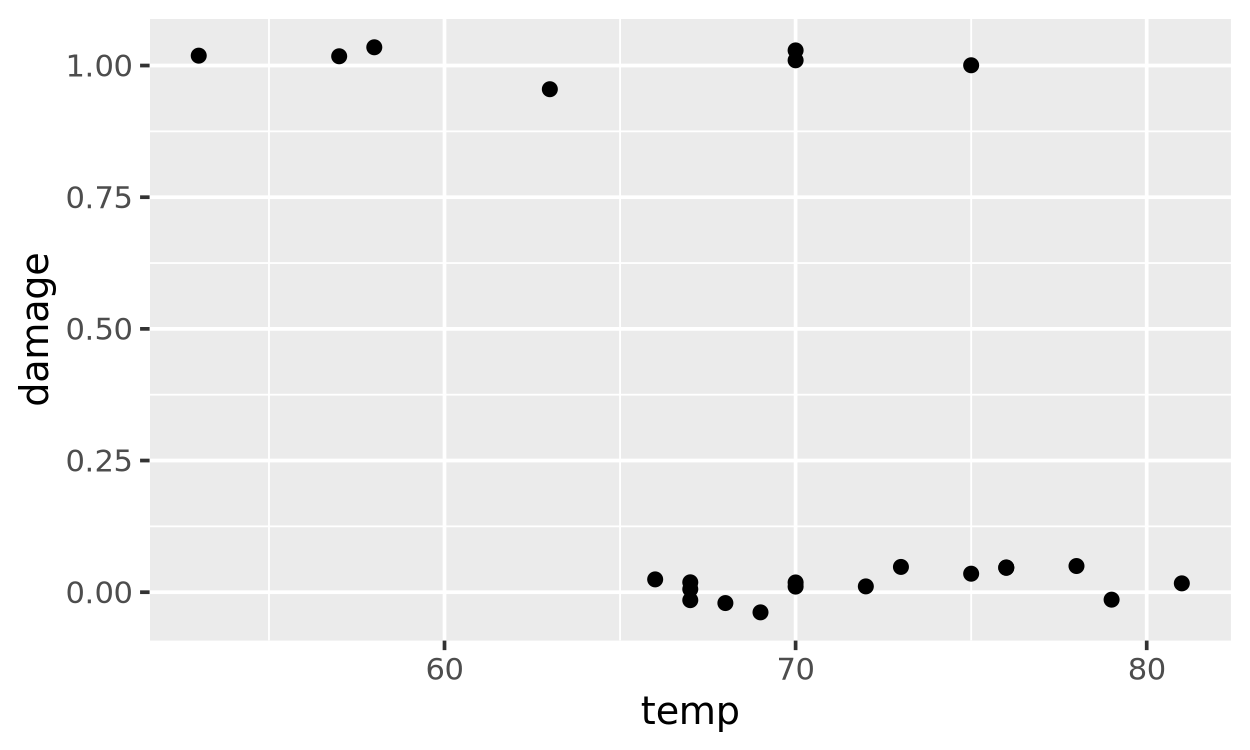

In [3]:
ggplot(challenger, aes(x = temp, y = damage)) +
    geom_jitter(width = 0, height = 0.05)

What do you see for the cold flights? For the warm flights?

**Answer:** The cold flights are the dangerous ones. Nearly every launch at low temperature (below about 65°F) has `damage = 1`, while the warm flights (above about 70°F) are mostly `damage = 0`. O-ring damage is strongly concentrated at low temperatures.

## 2. AI step: fit a logistic regression model

Open a terminal and run `opencode`. Your assistant has tools to add, edit, and run cells in this notebook.

**Copy this prompt into opencode:**

```text
I am working in exercises/11-challenger-exercise.ipynb, with R and tidymodels.
The data frame challenger has a column temp (launch temperature, °F) and a
column damage_f (a factor with levels "no" and "yes").

In the empty code cell in step 2, fit a logistic regression of damage_f ~ temp
with logistic_reg(). Save it as fit_oring and show tidy(fit_oring). Run the cell.
Use tidymodels only. Do not change any other cells.
```

**Your assistant puts its code in the cell below and runs it.** Read the code. Does it use `logistic_reg()`? Does it use `damage_f`, not `damage`?

In [4]:
fit_oring <- logistic_reg() |>
    fit(damage_f ~ temp, data = challenger)

tidy(fit_oring)

  term        estimate   std.error statistic p.value   
1 (Intercept) 15.0429016 7.3786301  2.038712 0.04147878
2 temp        -0.2321627 0.1082364 -2.144959 0.03195610

Is the `temp` slope positive or negative? What does that mean?

**Answer:** The `temp` slope is **negative** (−0.232). It is on the log-odds scale, so each extra 1°F lowers the log-odds of O-ring damage by 0.232. In odds terms the odds of damage are multiplied by exp(−0.232) ≈ 0.79 per degree, meaning warmer launches are less likely to damage an O-ring.

## 3. Predict at 31°F

Make a tibble with `temp = 31`. Predict with `fit_oring` and `type = 'prob'`.

<details>
<summary>Hint</summary>

```R
launch <- tibble(temp = 31)

fit_oring |> predict(new_data = launch, type = 'prob')
```

</details>

In [5]:
launch <- tibble(temp = 31)

fit_oring |> predict(new_data = launch, type = 'prob')

  .pred_no     .pred_yes
1 0.0003912171 0.9996088

**Check:** `.pred_yes` should be more than 0.99.

## 4. Plot the model

Make a grid with `temp = 30:85`. Predict on the grid with `type = 'prob'` and bind the grid to the predictions. Then plot the jittered data with `.pred_yes` as a line on top.

Add a vertical line at 31°F with `geom_vline(xintercept = 31, linetype = 'dashed')`.

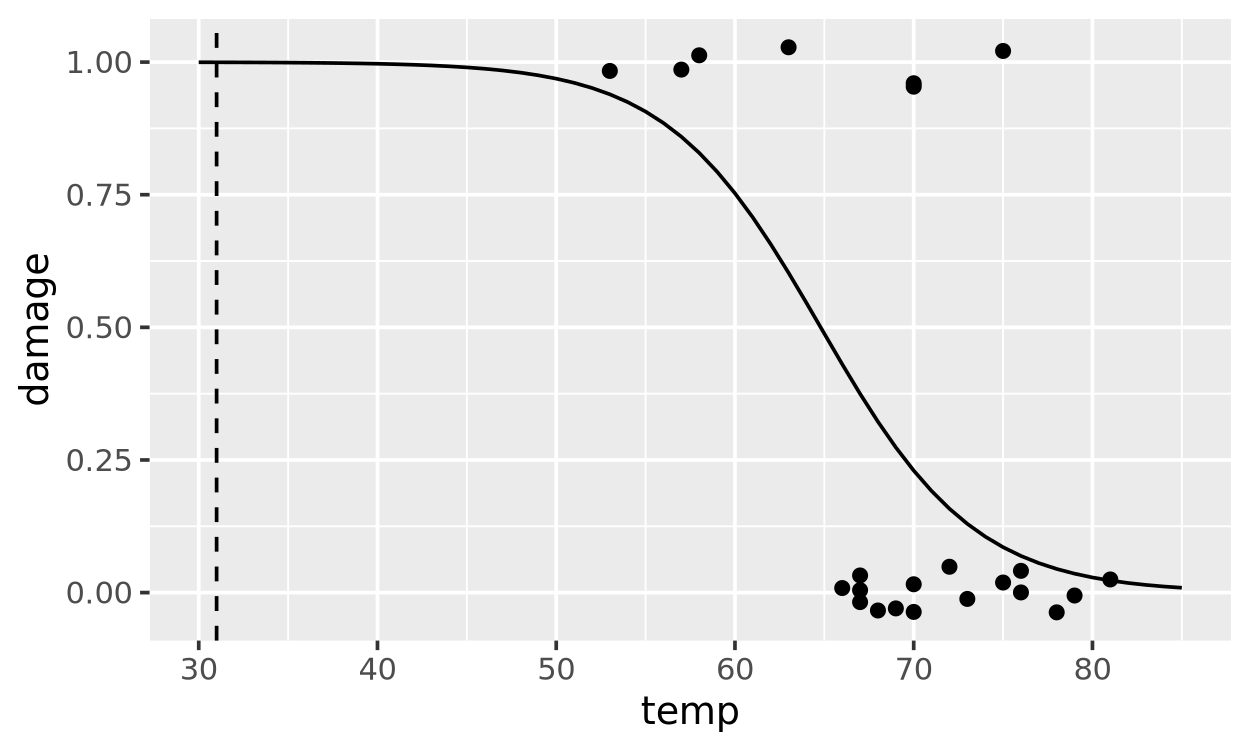

In [6]:
temp_grid <- tibble(temp = 30:85)

preds <- fit_oring |>
    predict(new_data = temp_grid, type = 'prob') |>
    bind_cols(temp_grid)

ggplot() +
    geom_jitter(data = challenger, aes(x = temp, y = damage), width = 0, height = 0.05) +
    geom_line(data = preds, aes(x = temp, y = .pred_yes)) +
    geom_vline(xintercept = 31, linetype = 'dashed')

**Check:** the curve should be near 1 at 30°F and near 0 at 85°F.